In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [31]:
file_number = 3

In [32]:
excel_fs = ['CMM 10 tulipes AAR3-33 tournées_analysis',
'CMM 30 tulipes brutes_analysis2',
'CMM batch O finished parts',
'CMM N1-N30 finished part Batch N']

n_of_results = [10, 30, 10, 30]

n_of_result = n_of_results[file_number]

In [33]:
excel_f = excel_fs[file_number]
data = pd.read_excel(f'../{excel_f}.xlsx', skiprows=7).iloc[:, 1:]
num_columns = data.shape[1] - 2  # columnas de valores
data.columns = ['nombre_variable', 'acronimo'] + [f'valor_{i}' for i in range(1, num_columns + 1)]
data

,nombre_variable,acronimo,valor_1,valor_2,valor_3,valor_4,valor_5,valor_6,valor_7,valor_8,...,valor_56,valor_57,valor_58,valor_59,valor_60,valor_61,valor_62,valor_63,valor_64,valor_65
0,NaN,Diff_SH_A_P3,0.0346,0.1094,0.1458,0.0070,0.0147,0.0093,0.0176,0.0277,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Measuring_plane_ME1,21.8400,21.8400,21.8400,21.8400,21.8400,21.8400,21.8400,21.8400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Measuring_plane_ME2,36.6400,36.6400,36.6400,36.6400,36.6400,36.6400,36.6400,36.6400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NOTE1610b,0.1063,0.0649,0.0754,0.0598,0.0697,0.0598,0.0533,0.0630,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0125
4,NaN,Diff_SH_A_P4,0.0298,0.1018,0.1619,0.0198,0.0124,0.0074,0.0097,0.0155,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,Outer face Distance A,OFA,40.3637,40.3654,40.3773,40.3609,40.3594,40.3493,40.3789,40.3503,...,NaN,NaN,NaN,NaN,0.0087,NaN,NaN,0.0081,0.0035,NaN
305,Outer face Distance B,OFB,40.3769,40.3755,40.3699,40.3769,40.3675,40.3477,40.3585,40.3699,...,0.0233,0.0188,NaN,NaN,NaN,0.0176,NaN,NaN,NaN,NaN
306,Outer face Distance C,OFC,40.3520,40.3796,40.3339,40.3700,40.3756,40.3577,40.3364,40.3677,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
307,RunOut Outer Diameter / Bore,RunExtvsBore,0.5764,0.4816,0.5497,0.6921,0.6119,0.5103,0.5533,0.6564,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
regex = r'Shoulder Distance Track (A|B|C)'
data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)]
data_f = data_f.dropna(axis=1)


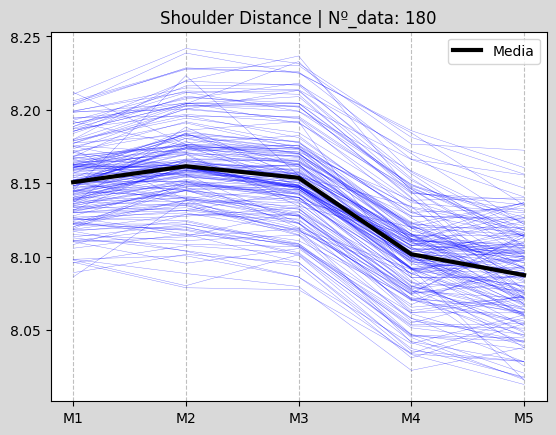

In [35]:
f, ax = plt.subplots(facecolor='.85')

all_curves = []
x = range(1, 6)
labels = ['M1', 'M2', 'M3', 'M4', 'M5']


pistas = ['A1', 'A2', 'B1', 'B2', 'C1', 'C2']
for pista in pistas:
    regex = f'Shoulder Distance Track {pista}'

    data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)].dropna(axis=1)
    data_f = data_f.sort_values('acronimo') #, ascending=False

    for i in range(2, 2+n_of_result):
        y = data_f.iloc[:, i].values

        ax.plot(range(1, 6), y, lw=0.3, color='b', alpha=0.5)

        all_curves.append(y)

for xpos in x:
     ax.axvline(xpos,color='gray',linestyle='--',lw=0.8,alpha=0.5,zorder=0)   

mean_curve = np.mean(np.vstack(all_curves), axis=0)

ax.set_title(f'Shoulder Distance | Nº_data: {len(all_curves)}')
ax.plot(range(1, 6),mean_curve,color='k',lw=3,label='Media')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.show()


In [36]:
regex = r'Pitch Circle Diameter'
data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)]
data_f = data_f.dropna(axis=1)
data_f

,nombre_variable,acronimo,valor_1,valor_2,valor_3,valor_4,valor_5,valor_6,valor_7,valor_8,...,valor_22,valor_23,valor_24,valor_25,valor_26,valor_27,valor_28,valor_29,valor_30,valor_31
59,Pitch Circle Diameter at ME1,PCD_ME1,54.6736,54.6682,54.6735,54.6784,54.6483,54.6629,54.6727,54.6560,...,54.6683,54.6704,54.6775,54.6801,54.6791,54.6548,54.6769,54.6723,54.6616,54.7
60,Pitch Circle Diameter at ME2,PCD_ME2,54.6937,54.6968,54.6871,54.6856,54.6684,54.6586,54.6895,54.6732,...,54.6873,54.6839,54.6883,54.6885,54.6770,54.6667,54.6870,54.6968,54.6635,54.7
61,Pitch Circle Diameter at ME3,PCD_ME3,54.6936,54.6938,54.6960,54.6942,54.6679,54.6782,54.6957,54.6727,...,54.6848,54.6827,54.6870,54.6865,54.6732,54.6655,54.6882,54.6925,54.6676,54.7
62,Pitch Circle Diameter at ME4,PCD_ME4,54.7419,54.7286,54.7254,54.7279,54.7050,54.7165,54.7137,54.7045,...,54.7168,54.7278,54.7144,54.7283,54.7148,54.7108,54.7339,54.7336,54.6948,54.7
63,Pitch Circle Diameter at ME5,PCD_ME5,54.7243,54.7204,54.7192,54.7143,54.7013,54.7060,54.7151,54.6932,...,54.7039,54.7181,54.7216,54.7170,54.6981,54.6954,54.7151,54.7045,54.6935,54.7


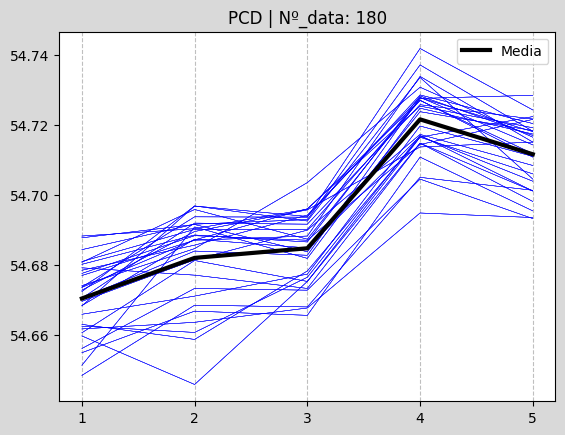

In [37]:
f, ax = plt.subplots(facecolor='.85')

all_curves = []
x = range(1, 6)
labels = ['M1', 'M2', 'M3', 'M4', 'M5']


pistas = ['A1', 'A2', 'B1', 'B2', 'C1', 'C2']
for pista in pistas:
    regex = r'Pitch Circle Diameter'

    data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)].dropna(axis=1)
    data_f = data_f.sort_values('acronimo') #, ascending=False

    for i in range(2, 2+n_of_result):
        y = data_f.iloc[:, i].values

        ax.plot(range(1, 6), y, lw=0.3, color='b', alpha=0.5)

        all_curves.append(y)

for xpos in x:
     ax.axvline(xpos,color='gray',linestyle='--',lw=0.8,alpha=0.5,zorder=0)   

mean_curve = np.mean(np.vstack(all_curves), axis=0)

ax.set_title(f'PCD | Nº_data: {len(all_curves)}')

ax.plot(range(1, 6),mean_curve,color='k',lw=3,label='Media')
ax.set_xticks(x)
# ax.set_xticklabels(labels)
ax.legend()
plt.show()


In [38]:
regex = r'F Pressure angle Track'
data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)]
data_f = data_f.dropna(axis=1)


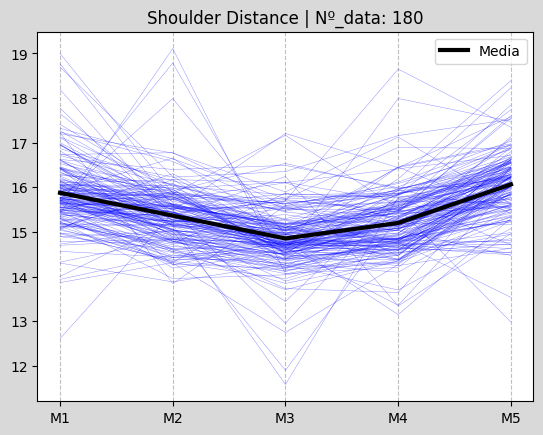

In [39]:
f, ax = plt.subplots(facecolor='.85')

all_curves = []
x = range(1, 6)
labels = ['M1', 'M2', 'M3', 'M4', 'M5']


pistas = ['A1', 'A2', 'B1', 'B2', 'C1', 'C2']
for pista in pistas:
    regex = f'F Pressure angle Track {pista}'

    data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)].dropna(axis=1)
    data_f = data_f.sort_values('acronimo') #, ascending=False

    for i in range(2, 2+n_of_result):
        y = data_f.iloc[:, i].values

        ax.plot(range(1, 6), y, lw=0.3, color='b', alpha=0.5)

        all_curves.append(y)

for xpos in x:
     ax.axvline(xpos,color='gray',linestyle='--',lw=0.8,alpha=0.5,zorder=0)   

mean_curve = np.mean(np.vstack(all_curves), axis=0)

ax.set_title(f'Shoulder Distance | Nº_data: {len(all_curves)}')
ax.plot(range(1, 6),mean_curve,color='k',lw=3,label='Media')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.show()


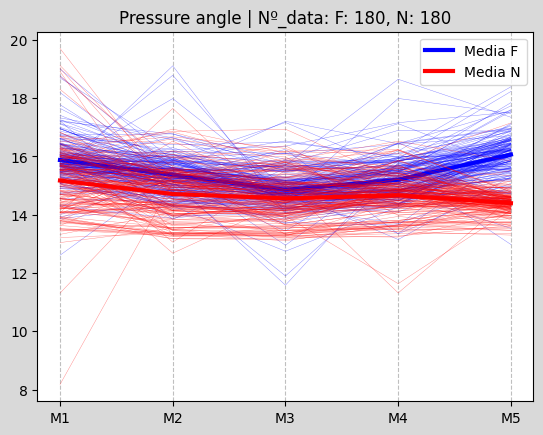

In [40]:
f, ax = plt.subplots(facecolor='.85')

x = range(1, 6)
labels = ['M1', 'M2', 'M3', 'M4', 'M5']
pistas = ['A1', 'A2', 'B1', 'B2', 'C1', 'C2']

# tipo: (color de las curvas, color de la media)
tipos = {'F': ('b', 'b'),
         'N': ('r', 'r')}

n_curvas = {}
for tipo, (c_curvas, c_media) in tipos.items():
    all_curves = []

    for pista in pistas:
        regex = f'{tipo} Pressure angle Track {pista}'

        data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)].dropna(axis=1)
        data_f = data_f.sort_values('acronimo')  # , ascending=False

        for i in range(2, 2 + n_of_result):
            y = data_f.iloc[:, i].values
            ax.plot(x, y, lw=0.3, color=c_curvas, alpha=0.5)
            all_curves.append(y)

    mean_curve = np.mean(np.vstack(all_curves), axis=0)
    ax.plot(x, mean_curve, color=c_media, lw=3, label=f'Media {tipo}')
    n_curvas[tipo] = len(all_curves)

for xpos in x:
    ax.axvline(xpos, color='gray', linestyle='--', lw=0.8, alpha=0.5, zorder=0)

ax.set_title('Pressure angle | Nº_data: ' + ', '.join(f'{t}: {n}' for t, n in n_curvas.items()))
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.show()

In [41]:
regex = 'Track (A|B|C)'
data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)]
data_f = data_f.dropna(axis=1)

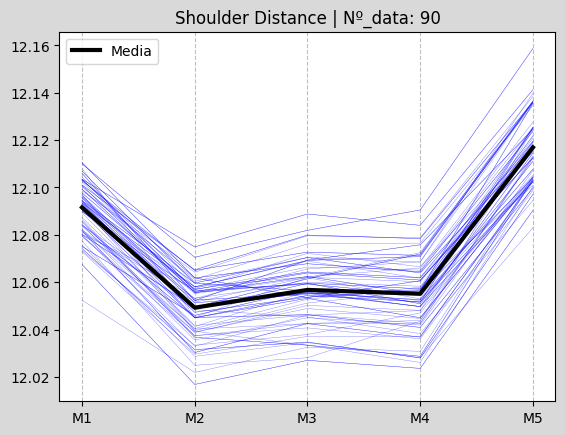

In [42]:
f, ax = plt.subplots(facecolor='.85')

all_curves = []
x = range(1, 6)
labels = ['M1', 'M2', 'M3', 'M4', 'M5']


pistas = ['A', 'A', 'B']
for pista in pistas:
    regex = f'Track {pista}'

    data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)].dropna(axis=1)
    data_f = data_f.sort_values('acronimo') #, ascending=False

    for i in range(2, 2+n_of_result):
        y = data_f.iloc[:, i].values

        ax.plot(range(1, 6), y, lw=0.3, color='b', alpha=0.5)

        all_curves.append(y)

for xpos in x:
     ax.axvline(xpos,color='gray',linestyle='--',lw=0.8,alpha=0.5,zorder=0)   

mean_curve = np.mean(np.vstack(all_curves), axis=0)

ax.set_title(f'Shoulder Distance | Nº_data: {len(all_curves)}')
ax.plot(range(1, 6),mean_curve,color='k',lw=3,label='Media')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.show()


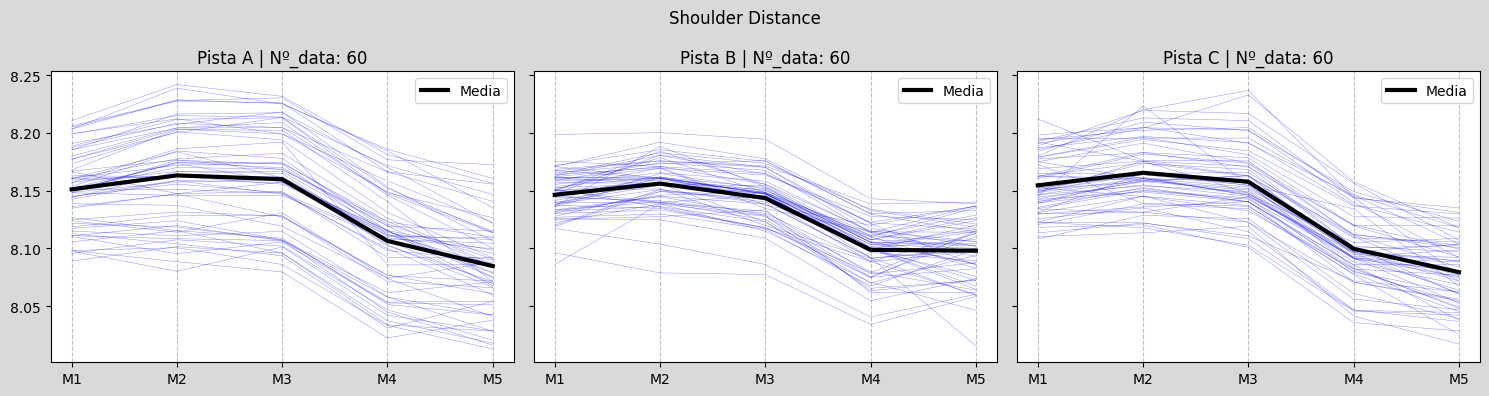

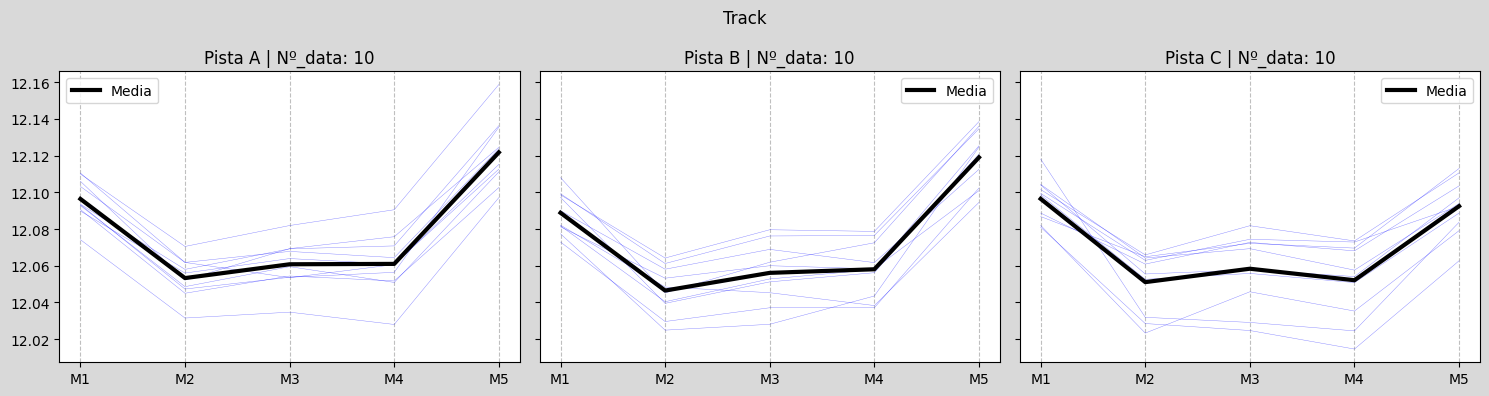

In [43]:
f, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, facecolor='.85')

x = range(1, 6)
labels = ['M1', 'M2', 'M3', 'M4', 'M5']

grupos = {'A': ['A1', 'A2'],
          'B': ['B1', 'B2'],
          'C': ['C1', 'C2']}

for ax, (grupo, pistas) in zip(axes, grupos.items()):
    all_curves = []

    for pista in pistas:
        regex = f'Shoulder Distance Track {pista}'

        data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)].dropna(axis=1)
        data_f = data_f.sort_values('acronimo')  # , ascending=False

        for i in range(2, 2 + n_of_result):
            y = data_f.iloc[:, i].values
            ax.plot(x, y, lw=0.3, color='b', alpha=0.5)
            all_curves.append(y)

    for xpos in x:
        ax.axvline(xpos, color='gray', linestyle='--', lw=0.8, alpha=0.5, zorder=0)

    mean_curve = np.mean(np.vstack(all_curves), axis=0)
    ax.plot(x, mean_curve, color='k', lw=3, label='Media')

    ax.set_title(f'Pista {grupo} | Nº_data: {len(all_curves)}')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()

f.suptitle('Shoulder Distance')
plt.tight_layout()
plt.show()

f, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, facecolor='.85')

x = range(1, 6)
labels = ['M1', 'M2', 'M3', 'M4', 'M5']

pistas = ['A', 'B', 'C']

for ax, pista in zip(axes, pistas):
    all_curves = []
    regex = f'Track {pista}'

    data_f = data[data.iloc[:, 0].astype(str).str.match(regex, na=False)].dropna(axis=1)
    data_f = data_f.sort_values('acronimo')  # , ascending=False

    for i in range(2, 2 + 10):
        y = data_f.iloc[:, i].values
        ax.plot(x, y, lw=0.3, color='b', alpha=0.5)
        all_curves.append(y)

    for xpos in x:
        ax.axvline(xpos, color='gray', linestyle='--', lw=0.8, alpha=0.5, zorder=0)

    mean_curve = np.mean(np.vstack(all_curves), axis=0)
    ax.plot(x, mean_curve, color='k', lw=3, label='Media')

    ax.set_title(f'Pista {pista} | Nº_data: {len(all_curves)}')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()

f.suptitle('Track')
plt.tight_layout()
plt.show()

